# 03 · Which tech companies announce layoffs? A first layoff-risk baseline

**Question.** Using only what a public company has reported in its filings, can we rank US tech companies by how likely they are to appear in the layoff tracker in the next two quarters, and what does the ranking depend on?

**Setup in one paragraph.** One row = one tech company (SEC SIC codes 357x, 366x, 367x, 737x) in one calendar quarter *t*. Features come from the filing quarter *t-1* (the report for *t* is not public yet). The label is 1 if the tracker lists a layoff at the company in quarter *t+1* or *t+2*. We train on rows up to 2022Q4 and test on 2023Q1 onward; the last two training quarters are dropped because their labels already look into the test period.

**Read this first.** The numbers quoted in the text are from the run of 2026-10-24. Re-running the notebook on the same data gives the same numbers (fixed seeds).

In [10]:
from pathlib import Path
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)      # the project's data paths are relative to the repo root
from analysis import company_models as cm
from analysis.company_panel import FEATURES
PROCESSED = ROOT / "data" / "processed"

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold"})
def save(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

panel = pd.read_csv(PROCESSED / "company_panel.csv", dtype={"sic": str, "sic2": str})
print(f"{len(panel):,} company-quarters | {panel['cik'].nunique()} companies | "
      f"{int(panel['y_next2q'].sum())} positive rows | base rate {panel['y_next2q'].mean():.2%}")

14,723 company-quarters | 869 companies | 648 positive rows | base rate 4.40%


## 1 · The panel: how often does a tech company show up in the tracker?

The tracker only starts in 2020 and the big wave came in 2022, so early quarters have almost no positives. That is why the time split matters: a model trained on 2020-2021 has seen very few layoffs.

,rows,positives,rate
year,,,
2020,2452,17,0.0069
2021,2544,8,0.0031
2022,2518,237,0.0941
2023,2420,159,0.0657
2024,2276,105,0.0461
2025,2096,96,0.0458
2026,417,26,0.0624


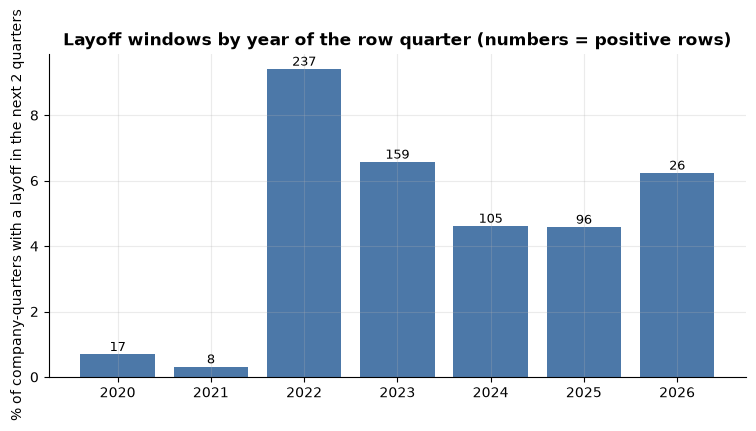

In [11]:
by_year = panel.assign(year=panel["quarter"].str[:4]).groupby("year")["y_next2q"].agg(rows="size", positives="sum", rate="mean")
display(by_year.round(4))

fig, ax = plt.subplots()
ax.bar(by_year.index, 100 * by_year["rate"], color="#4C78A8")
for x, (r, n) in zip(by_year.index, zip(by_year["rate"], by_year["positives"])):
    ax.text(x, 100 * r + 0.1, f"{int(n)}", ha="center", fontsize=9)
ax.set_ylabel("% of company-quarters with a layoff in the next 2 quarters")
ax.set_title("Layoff windows by year of the row quarter (numbers = positive rows)")
save(fig, "03_base_rate_by_year.png"); plt.show()

## 2 · Models and what beats what

Two deliberately small models: an L2 logistic regression and a shallow gradient-boosted tree. Everything estimated (clipping, medians, scaling, the models) uses training rows only. Confidence intervals resample **whole companies**, because rows of one company are strongly correlated.

We also refit both models **without company size** (log of total assets) to see whether anything else carries signal.

In [12]:
sc = cm.run_size_control(panel, embargo=True, n_boot=300)
res = sc["with_size"]
tr, te = res["train"], res["test"]
print(f"Train: {len(tr):,} rows, {int(tr['y_next2q'].sum())} positives ({tr['y_next2q'].mean():.2%})")
print(f"Test : {len(te):,} rows, {int(te['y_next2q'].sum())} positives ({te['y_next2q'].mean():.2%}), "
      f"{te.loc[te['y_next2q']==1, 'cik'].nunique()} companies with a positive")
overall = sc["overall"].set_index("model")
size_only = res["baselines"].set_index("feature").loc["log_assets"]
display(overall.round(4))
print(f"log assets alone (no model): PR-AUC {size_only['pr_auc']:.4f}, ROC-AUC {size_only['roc_auc']:.4f}")

Train: 6,210 rows, 100 positives (1.61%)
Test : 7,209 rows, 386 positives (5.35%), 131 companies with a positive


,pr_auc,ci_lo,ci_hi,lift,roc_auc,brier
model,,,,,,
constant (train base rate),0.0535,NaN,NaN,1.0000,0.5000,0.0521
logit_size,0.2187,0.1360,0.2986,4.0853,0.8047,0.0496
gb_size,0.1490,0.1113,0.1933,2.7822,0.7810,0.0502
logit_nosize,0.0794,0.0661,0.0995,1.4833,0.6610,0.0515
gb_nosize,0.0875,0.0727,0.1096,1.6348,0.6699,0.0516


log assets alone (no model): PR-AUC 0.2827, ROC-AUC 0.7747


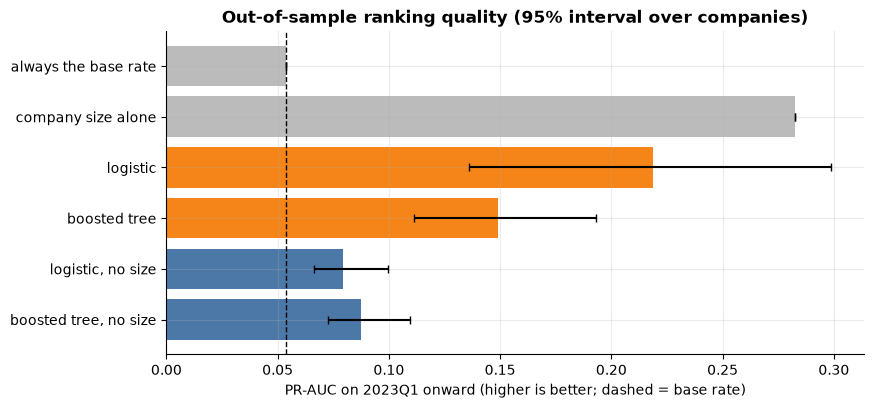

In [13]:
labels = ["always the base rate", "company size alone", "logistic", "boosted tree", "logistic, no size", "boosted tree, no size"]
vals = [overall.loc["constant (train base rate)", "pr_auc"], size_only["pr_auc"], overall.loc["logit_size", "pr_auc"],
        overall.loc["gb_size", "pr_auc"], overall.loc["logit_nosize", "pr_auc"], overall.loc["gb_nosize", "pr_auc"]]
keys = [None, None, "logit_size", "gb_size", "logit_nosize", "gb_nosize"]
err = [[0, 0] if k is None else [overall.loc[k, "pr_auc"] - overall.loc[k, "ci_lo"], overall.loc[k, "ci_hi"] - overall.loc[k, "pr_auc"]] for k in keys]
fig, ax = plt.subplots()
ax.barh(labels[::-1], vals[::-1], xerr=np.array(err).T[:, ::-1], color=["#BBBBBB", "#BBBBBB", "#F58518", "#F58518", "#4C78A8", "#4C78A8"][::-1], capsize=3)
ax.axvline(vals[0], color="k", ls="--", lw=1)
ax.set_xlabel("PR-AUC on 2023Q1 onward (higher is better; dashed = base rate)")
ax.set_title("Out-of-sample ranking quality (95% interval over companies)")
save(fig, "03_pr_auc.png"); plt.show()

## 3 · Is anything besides size doing the work? Compare inside size groups

Test rows are split into three size groups using the *training* terciles of log assets. Inside a group, size is roughly held constant. Groups with fewer than 15 positives are left blank.

model,gb_nosize,gb_size,logit_nosize,logit_size,rows,positives,base_rate
size_group,,,,,,,
1,NaN,NaN,NaN,NaN,2486,14,0.0056
2,1.46,1.61,1.57,1.72,2008,96,0.0478
3,1.35,1.92,1.25,2.64,2715,276,0.1017


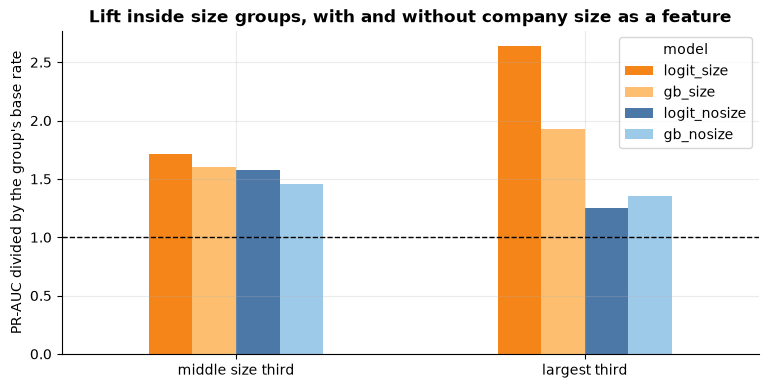

In [14]:
st = sc["stratified"]
display(st.pivot(index="size_group", columns="model", values="lift").round(2).assign(
    rows=st.groupby("size_group")["rows"].first(), positives=st.groupby("size_group")["positives"].first(),
    base_rate=st.groupby("size_group")["base_rate"].first().round(4)))

g = st[st["size_group"].isin([2, 3])].pivot(index="size_group", columns="model", values="lift")
fig, ax = plt.subplots()
g[["logit_size", "gb_size", "logit_nosize", "gb_nosize"]].plot.bar(ax=ax, rot=0, color=["#F58518", "#FDBF6F", "#4C78A8", "#9ecae9"])
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xticklabels(["middle size third", "largest third"]); ax.set_xlabel("")
ax.set_ylabel("PR-AUC divided by the group's base rate")
ax.set_title("Lift inside size groups, with and without company size as a feature")
save(fig, "03_lift_by_size_group.png"); plt.show()

## 4 · What do the models use?

In [15]:
print("Logistic regression (with size): effect per 1 standard deviation")
display(res["coefficients"].head(8).round(3))
print("Logistic regression WITHOUT size")
display(sc["without_size"]["coefficients"].head(8).round(3))
print("Single features on their own, direction chosen on training rows")
display(res["baselines"].round(4))

Logistic regression (with size): effect per 1 standard deviation


,feature,coef,odds_ratio
0,log_assets,1.382,3.984
1,sic_73,0.974,2.649
2,log_assets_missing,-0.933,0.393
3,sic_36,-0.889,0.411
4,op_margin_missing,-0.827,0.437
5,cash_assets_missing,-0.593,0.552
6,rev_qoq_missing,0.525,1.690
7,rev_yoy_missing,0.450,1.569


Logistic regression WITHOUT size


,feature,coef,odds_ratio
0,cash_assets_missing,-1.226,0.293
1,sic_36,-1.054,0.349
2,sic_73,0.898,2.456
3,op_margin_missing,-0.793,0.453
4,sga_ratio_missing,-0.658,0.518
5,op_margin,0.588,1.801
6,rnd_ratio_missing,-0.517,0.596
7,rev_qoq,-0.294,0.745


Single features on their own, direction chosen on training rows


,feature,direction,pr_auc,roc_auc
0,log_assets,higher = riskier,0.2827,0.7747
1,gross_margin,higher = riskier,0.0755,0.6396
2,rnd_ratio,higher = riskier,0.0549,0.5329
3,rev_yoy,higher = riskier,0.0527,0.5247
4,sga_ratio,higher = riskier,0.0516,0.4982
5,cash_assets,higher = riskier,0.0487,0.4851
6,net_loss,higher = riskier,0.0483,0.4353
7,rev_qoq,lower = riskier,0.0482,0.4856
8,op_margin,lower = riskier,0.0412,0.4010


## 5 · Calibration: the ranking transfers, the probabilities do not

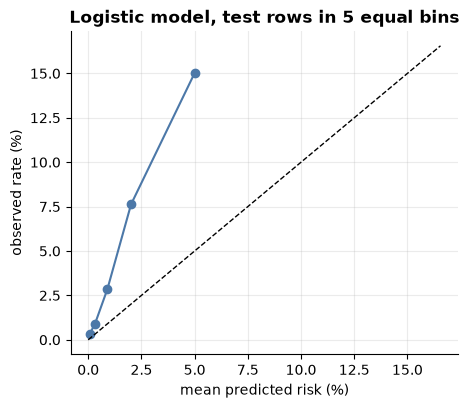

mean predicted 0.017 vs observed 0.054


,bin,n,predicted,observed
0,0,1442,0.0008,0.0035
1,1,1442,0.0032,0.0090
2,2,1441,0.0090,0.0285
3,3,1442,0.0201,0.0763
4,4,1442,0.0501,0.1505


In [16]:
cal = res["calibration"]["logit"]
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.plot(100 * cal["predicted"], 100 * cal["observed"], "o-", color="#4C78A8")
m = max(100 * cal["observed"].max(), 100 * cal["predicted"].max()) * 1.1
ax.plot([0, m], [0, m], "k--", lw=1)
ax.set_xlabel("mean predicted risk (%)"); ax.set_ylabel("observed rate (%)")
ax.set_title("Logistic model, test rows in 5 equal bins")
save(fig, "03_calibration.png"); plt.show()
print(f"mean predicted {res['scores']['logit'].mean():.3f} vs observed {te['y_next2q'].mean():.3f}")
display(cal.round(4))

## 6 · What we can and cannot say

**Results of the 2026-10-30 run**, with the larger company matching (350 layoff companies matched to SEC filers, 848 events). Training rows up to 2022Q2 (100 positives); test rows from 2023Q1: 7,209 company-quarters, 386 positives from 131 companies, base rate 5.4%. (The first run, with 204 matched companies, gave the same picture.)

1. **Ranking by filing data beats chance.** The logistic model reaches PR-AUC 0.22 (95% interval 0.14 to 0.30) against a base rate of 0.054, about 4 times better. The boosted tree is weaker (0.15, interval 0.11 to 0.19) and less stable.
2. **Most of that is company size.** Total assets alone give PR-AUC 0.28, at least as good as either model. Without size the models fall to 0.079 (logistic) and 0.088 (tree), about 1.5 times the base rate (intervals 0.07 to 0.11).
3. **Inside size groups the picture is the same.** In the smallest third the tracker has 14 positives in 2,486 rows (0.6%), too few to evaluate any model. In the middle third the models give about 1.5 to 1.7 times the base rate with or without size. In the largest third, the models that include size reach 2.6 times (logistic) and 1.9 times (tree), without size only about 1.3 to 1.4 times. Size still matters *within* the largest third, so it is not just a threshold.
4. **Fundamentals add little.** Revenue growth, net loss, cash ratios and R&D on their own are close to the base rate (PR-AUC 0.04 to 0.06); gross margin is the best at 0.076. Operating margin is not stable: in the training years lower margins went with more layoffs, in the test years higher margins did, and the model's coefficient for it is positive (odds ratio about 1.8 per standard deviation without size). Treat any story about it (for example profitable big companies cutting costs) as a guess, not a finding.
5. **Industry matters.** Software and IT services (SIC 73) carry higher risk than hardware and semiconductors (SIC 36): odds ratios about 2.5 and 0.35 without size.
6. **Use the scores as a ranking, not as probabilities.** Predicted risk is about three times too low on average (0.017 against 0.054) because training mostly covers the quiet period before the 2022 wave. The observed rate still rises from 0.4% in the lowest bin to 15% in the highest.

**Limits.**
- **The label is "appears in the layoff tracker", not "has layoffs".** The tracker records mostly notable layoffs, so large, well-known companies are more likely to be listed at all. The size effect may be partly a reporting effect. We have not tested this.
- **Few positives early.** There are only 100 positive rows in the training period (the first matching had 55), almost all from 2022. Results move when the two embargoed quarters are added back (tree 0.15 to 0.20, logistic 0.22 to 0.24), so treat small differences between models as noise.
- **Rows overlap.** Neighbouring quarters of one company share most of their label window, so the effective sample is closer to the 131 positive companies than to 386 positive rows.
- **Company matching is imperfect.** 55 of the 358 matches were flagged as fuzzy or ambiguous, and Post-IPO companies that were delisted or foreign are not matched; unmatched companies are labelled "no layoff".
- **Scope.** US-listed SEC filers in four SIC groups only; foreign filers (such as ASML or SAP) are missing; financials are calendar-aligned approximations of fiscal quarters; derived gross profit and SG&A are approximate for some companies.
- **No causal claim.** Nothing here shows what makes a company lay people off.

**Next steps worth considering:** separate "large, profitable cost-cutters" from "distressed small companies" instead of one model; add the macro conditions from notebook 04; and check the 55 flagged matches by hand.